In [ ]:
# Q1.

[nltk_data] Downloading package punkt to C:\Users\Adhya
[nltk_data]     Razdan\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package punkt_tab to C:\Users\Adhya
[nltk_data]     Razdan\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.
[nltk_data] Downloading package punkt_tab to C:\Users\Adhya
[nltk_data]     Razdan\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to C:\Users\Adhya
[nltk_data]     Razdan\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


Cleaned Text:
 
i love reading books about mythology and ancient mysteries
greek mythology tells fascinating stories about gods and heroes
these stories explore courage wisdom love and betrayal
ancient legends often explain natural events and human behavior
i enjoy discovering hidden meanings in these timeless tales
reading mythology makes history more interesting and imaginative


Sentence Tokens: ['\nI love reading books about mythology and ancient mysteries.', 'Greek mythology tells fascinating stories about gods and heroes.', 'These stories explore courage, wisdom, love, and betrayal.', 'Ancient legends often explain natural events and human behavior.', 'I enjoy discovering hidden meanings in these timeless tales.', 'Reading mythology makes history more interesting and imaginative.']

Word Tokens: ['i', 'love', 'reading', 'books', 'about', 'mythology', 'and', 'ancient', 'mysteries', 'greek', 'mythology', 'tells', 'fascinating', 'stories', 'about', 'gods', 'and', 'heroes', 'these', 

<Axes: title={'center': 'Top 10 Words After Stopword Removal'}, xlabel='Samples', ylabel='Counts'>

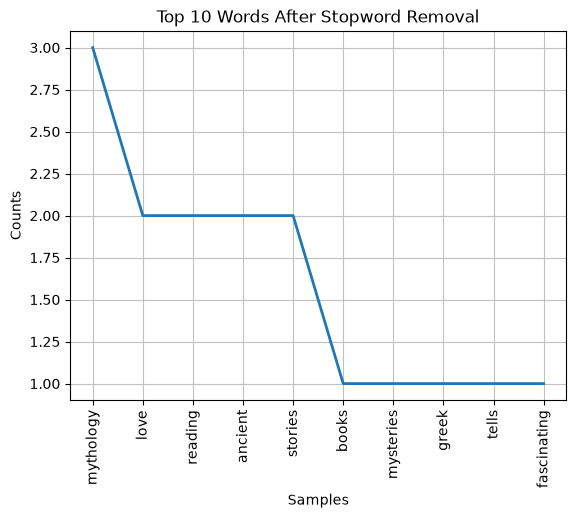

In [1]:
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

text = """
I love reading books about mythology and ancient mysteries.
Greek mythology tells fascinating stories about gods and heroes.
These stories explore courage, wisdom, love, and betrayal.
Ancient legends often explain natural events and human behavior.
I enjoy discovering hidden meanings in these timeless tales.
Reading mythology makes history more interesting and imaginative.
"""

clean_text = re.sub(r'[^\w\s]', '', text.lower())
print("Cleaned Text:\n", clean_text)

sentences = sent_tokenize(text)
words = word_tokenize(clean_text)

print("\nSentence Tokens:", sentences)
print("\nWord Tokens:", words)

print("\nPython split():", clean_text.split())
print("\nNLTK word_tokenize():", word_tokenize(text.lower()))

stop_words = set(stopwords.words('english'))
filtered_words = [
    word for word in words
    if word.isalpha() and word not in stop_words
]
print("\nWords after Stopword Removal:", filtered_words)

freq = FreqDist(filtered_words)
print("\nWord Frequencies:")
for word, count in freq.most_common():
    print(word, ":", count)

freq.plot(10, title="Top 10 Words After Stopword Removal")

In [ ]:
# Q2.

In [2]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

text = """
I love reading books about mythology and ancient mysteries.
Greek mythology tells fascinating stories about gods and heroes.
These stories explore courage, wisdom, love, and betrayal.
Ancient legends often explain natural events and human behavior.
I enjoy discovering hidden meanings in these timeless tales.
Reading mythology makes history more interesting and imaginative.
"""

words = re.findall(r'\b[a-zA-Z]+\b', text.lower())
print("Alphabetic Words:\n", words)

stop_words = set(stopwords.words('english'))
filtered_words = [w for w in words if w not in stop_words]
print("\nAfter Stopword Removal:\n", filtered_words)

stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(w) for w in filtered_words]
print("\nStemmed Words:\n", stemmed_words)

lemmatizer = WordNetLemmatizer()
lemmatized_words = [
    lemmatizer.lemmatize(w) for w in filtered_words
]
print("\nLemmatized Words:\n", lemmatized_words)

print("\nComparison:")
for original, stem, lemma in zip(
    filtered_words, stemmed_words, lemmatized_words
):
    print(f"{original:15} {stem:15} {lemma}")

[nltk_data] Downloading package stopwords to C:\Users\Adhya
[nltk_data]     Razdan\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to C:\Users\Adhya
[nltk_data]     Razdan\AppData\Roaming\nltk_data...
[nltk_data] Downloading package omw-1.4 to C:\Users\Adhya
[nltk_data]     Razdan\AppData\Roaming\nltk_data...


Alphabetic Words:
 ['i', 'love', 'reading', 'books', 'about', 'mythology', 'and', 'ancient', 'mysteries', 'greek', 'mythology', 'tells', 'fascinating', 'stories', 'about', 'gods', 'and', 'heroes', 'these', 'stories', 'explore', 'courage', 'wisdom', 'love', 'and', 'betrayal', 'ancient', 'legends', 'often', 'explain', 'natural', 'events', 'and', 'human', 'behavior', 'i', 'enjoy', 'discovering', 'hidden', 'meanings', 'in', 'these', 'timeless', 'tales', 'reading', 'mythology', 'makes', 'history', 'more', 'interesting', 'and', 'imaginative']

After Stopword Removal:
 ['love', 'reading', 'books', 'mythology', 'ancient', 'mysteries', 'greek', 'mythology', 'tells', 'fascinating', 'stories', 'gods', 'heroes', 'stories', 'explore', 'courage', 'wisdom', 'love', 'betrayal', 'ancient', 'legends', 'often', 'explain', 'natural', 'events', 'human', 'behavior', 'enjoy', 'discovering', 'hidden', 'meanings', 'timeless', 'tales', 'reading', 'mythology', 'makes', 'history', 'interesting', 'imaginative']

S

In [ ]:
# Q3.

In [3]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "Artificial intelligence helps computers learn and solve problems.",
    "Machine learning uses data to build intelligent computer systems.",
    "Artificial intelligence and machine learning improve data analysis."
]

count_vectorizer = CountVectorizer()
bow_matrix = count_vectorizer.fit_transform(texts)

print("Bag of Words Vocabulary:")
print(count_vectorizer.get_feature_names_out())

print("\nBag of Words Matrix:")
print(bow_matrix.toarray())

tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

feature_names = tfidf_vectorizer.get_feature_names_out()

print("\nTF-IDF Matrix:")
print(tfidf_matrix.toarray().round(3))

print("\nTop 3 Keywords for Each Text:")

for i, row in enumerate(tfidf_matrix.toarray()):
    top_indices = row.argsort()[-3:][::-1]

    print(f"\nText {i + 1}: {texts[i]}")
    for index in top_indices:
        print(feature_names[index], ":", round(row[index], 3))

Bag of Words Vocabulary:
['analysis' 'and' 'artificial' 'build' 'computer' 'computers' 'data'
 'helps' 'improve' 'intelligence' 'intelligent' 'learn' 'learning'
 'machine' 'problems' 'solve' 'systems' 'to' 'uses']

Bag of Words Matrix:
[[0 1 1 0 0 1 0 1 0 1 0 1 0 0 1 1 0 0 0]
 [0 0 0 1 1 0 1 0 0 0 1 0 1 1 0 0 1 1 1]
 [1 1 1 0 0 0 1 0 1 1 0 0 1 1 0 0 0 0 0]]

TF-IDF Matrix:
[[0.    0.293 0.293 0.    0.    0.385 0.    0.385 0.    0.293 0.    0.385
  0.    0.    0.385 0.385 0.    0.    0.   ]
 [0.    0.    0.    0.36  0.36  0.    0.273 0.    0.    0.    0.36  0.
  0.273 0.273 0.    0.    0.36  0.36  0.36 ]
 [0.428 0.325 0.325 0.    0.    0.    0.325 0.    0.428 0.325 0.    0.
  0.325 0.325 0.    0.    0.    0.    0.   ]]

Top 3 Keywords for Each Text:

Text 1: Artificial intelligence helps computers learn and solve problems.
learn : 0.385
problems : 0.385
solve : 0.385

Text 2: Machine learning uses data to build intelligent computer systems.
uses : 0.36
to : 0.36
systems : 0.36

Text 3: 

In [ ]:
# Q4.

In [4]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text1 = """
Artificial intelligence enables machines to learn from data.
AI systems recognize patterns and solve complex problems.
They are widely used in healthcare, education, and automation.
Machine learning improves predictions using historical data.
AI helps businesses make intelligent decisions.
"""

text2 = """
Blockchain is a distributed digital ledger technology.
It stores transactions securely across multiple computers.
Blockchain provides transparency and prevents data tampering.
It is commonly used in cryptocurrencies and smart contracts.
Blockchain improves trust and security in digital transactions.
"""

def preprocess(text):
    text = text.lower()
    return re.findall(r'\b[a-z]+\b', text)

tokens1 = preprocess(text1)
tokens2 = preprocess(text2)

print("Tokens in Text 1:\n", tokens1)
print("\nTokens in Text 2:\n", tokens2)

set1 = set(tokens1)
set2 = set(tokens2)

jaccard = len(set1 & set2) / len(set1 | set2)

print("\nJaccard Similarity:", round(jaccard, 4))

vectorizer = TfidfVectorizer()

tfidf_matrix = vectorizer.fit_transform([text1, text2])

cosine = cosine_similarity(
    tfidf_matrix[0:1],
    tfidf_matrix[1:2]
)[0][0]

print("Cosine Similarity:", round(cosine, 4))

print("\nComparison:")
if jaccard > cosine:
    print("Jaccard similarity is higher.")
elif cosine > jaccard:
    print("Cosine similarity is higher.")
else:
    print("Both similarities are equal.")

Tokens in Text 1:
 ['artificial', 'intelligence', 'enables', 'machines', 'to', 'learn', 'from', 'data', 'ai', 'systems', 'recognize', 'patterns', 'and', 'solve', 'complex', 'problems', 'they', 'are', 'widely', 'used', 'in', 'healthcare', 'education', 'and', 'automation', 'machine', 'learning', 'improves', 'predictions', 'using', 'historical', 'data', 'ai', 'helps', 'businesses', 'make', 'intelligent', 'decisions']

Tokens in Text 2:
 ['blockchain', 'is', 'a', 'distributed', 'digital', 'ledger', 'technology', 'it', 'stores', 'transactions', 'securely', 'across', 'multiple', 'computers', 'blockchain', 'provides', 'transparency', 'and', 'prevents', 'data', 'tampering', 'it', 'is', 'commonly', 'used', 'in', 'cryptocurrencies', 'and', 'smart', 'contracts', 'blockchain', 'improves', 'trust', 'and', 'security', 'in', 'digital', 'transactions']

Jaccard Similarity: 0.0847
Cosine Similarity: 0.1368

Comparison:
Cosine similarity is higher.


In [ ]:
# Q5.


Review: This phone has an excellent camera and amazing battery life.
Polarity: 0.8
Subjectivity: 0.95
Sentiment: Positive

Review: I love this product because it is fast and easy to use.
Polarity: 0.378
Subjectivity: 0.678
Sentiment: Positive

Review: The laptop works perfectly and provides excellent performance.
Polarity: 1.0
Subjectivity: 1.0
Sentiment: Positive

Review: The product is terrible and stopped working after two days.
Polarity: -1.0
Subjectivity: 1.0
Sentiment: Negative

Review: The battery is poor and the phone becomes very slow.
Polarity: -0.395
Subjectivity: 0.56
Sentiment: Negative

Review: The service was disappointing and the quality was bad.
Polarity: -0.65
Subjectivity: 0.683
Sentiment: Negative

Review: The product is okay and works as expected.
Polarity: 0.2
Subjectivity: 0.45
Sentiment: Positive

Review: The delivery was average and nothing special.
Polarity: 0.104
Subjectivity: 0.486
Sentiment: Positive


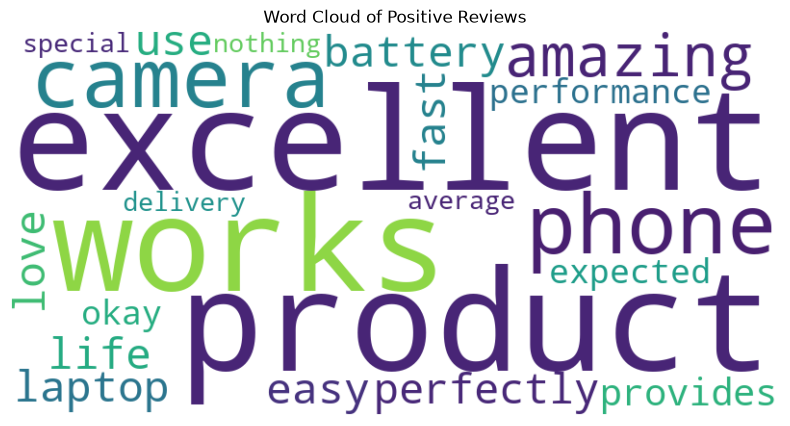

In [ ]:
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

reviews = [
    "This phone has an excellent camera and amazing battery life.",
    "I love this product because it is fast and easy to use.",
    "The laptop works perfectly and provides excellent performance.",
    "The product is terrible and stopped working after two days.",
    "The battery is poor and the phone becomes very slow.",
    "The service was disappointing and the quality was bad.",
    "The product is okay and works as expected.",
    "The delivery was average and nothing special."
]

positive_reviews = []

for review in reviews:
    blob = TextBlob(review)

    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity

    if polarity > 0:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print("\nReview:", review)
    print("Polarity:", round(polarity, 3))
    print("Subjectivity:", round(subjectivity, 3))
    print("Sentiment:", sentiment)

if positive_reviews:
    positive_text = " ".join(positive_reviews)

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white"
    ).generate(positive_text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud of Positive Reviews")
    plt.show()
else:
    print("No positive reviews found.")

In [ ]:
# Q6.

In [6]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

text = """
Technology continues to change the way people live and work.
Artificial intelligence helps computers learn from data and solve problems.
Machine learning allows systems to recognize patterns and make predictions.
Deep learning uses neural networks to process complex information.
These technologies are used in healthcare, education, agriculture, and business.
They help doctors detect diseases and help students learn effectively.
Computers can analyze large datasets faster than humans.
However, technology must be developed responsibly and ethically.
Privacy, security, and fairness are important considerations.
Researchers continue to improve intelligent systems every day.
In the future, technology may help solve many global challenges.
People must learn new skills to adapt to technological changes.
Education and innovation will remain important for future generations.
Artificial intelligence can support human creativity and decision making.
The best technology should improve people's lives.
"""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1

print("Vocabulary Size:", total_words)

input_sequences = []

for line in text.lower().split("."):
    line = line.strip()

    if not line:
        continue

    token_list = tokenizer.texts_to_sequences([line])[0]

    for i in range(1, len(token_list)):
        ngram_sequence = token_list[:i + 1]
        input_sequences.append(ngram_sequence)

max_sequence_len = max(len(seq) for seq in input_sequences)

input_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_len,
    padding="pre"
)

X = input_sequences[:, :-1]
y = input_sequences[:, -1]

y = tf.keras.utils.to_categorical(y, num_classes=total_words)

print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

model = Sequential([
    Embedding(total_words, 32, input_length=max_sequence_len - 1),
    LSTM(64),
    Dense(total_words, activation="softmax")
])

model.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

model.fit(X, y, epochs=100, verbose=0)

print("\nModel Training Completed!")

def generate_text(seed_text, next_words=10):
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([seed_text])[0]

        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_len - 1,
            padding="pre"
        )

        predicted_probabilities = model.predict(
            token_list, verbose=0
        )[0]

        predicted_word_index = np.argmax(predicted_probabilities)

        output_word = None

        for word, index in tokenizer.word_index.items():
            if index == predicted_word_index:
                output_word = word
                break

        if output_word is None:
            break

        seed_text += " " + output_word

    return seed_text

print("\nGenerated Text:")
print(generate_text("technology", 10))
print(generate_text("artificial", 10))
print(generate_text("learning", 10))

Vocabulary Size: 99
Input Shape: (120, 9)
Target Shape: (120, 99)


c:\Users\Adhya Razdan\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(



Model Training Completed!

Generated Text:
technology must technology to improve systems every many global challenges challenges
artificial intelligence can support human creativity and decision making problems problems
learning learning to to to recognize patterns make information predictions predictions
